<a href="https://colab.research.google.com/github/BrianAyekha/-connection-of-MySQL-database-to-NodeJs/blob/main/Model_Evaluation_Interpretation_Deployment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Evaluation, Interpretation and Deployment Readiness
**Project:** Early fault detection and diagnosis in hospital electromechanical equipment (infant warmer case study)

**Model:** Random Forest classifier predicting `Machine failure` from sensor features

**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI, id 601), used as a stand-in for infant warmer sensor data.

**Author:** Brian Ayekha Mwangala

## 1. Load the data and prepare the train/test split

In [1]:
!pip install -q ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay, classification_report)

ai4i = fetch_ucirepo(id=601)
df = pd.concat([ai4i.data.features, ai4i.data.targets], axis=1)

# Same features and target as before. Failure-mode columns are NOT used (they would leak the answer).
numeric_cols = ["Air temperature", "Process temperature", "Rotational speed", "Torque", "Tool wear"]
categorical_cols = ["Type"]
X = df[numeric_cols + categorical_cols].copy()
# Use floats for all numeric columns (partial dependence plots do not accept integer columns)
X[numeric_cols] = X[numeric_cols].astype(float)
y = df["Machine failure"]

# Stratified split keeps the rare failure class in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "failures:", y_train.sum(), "| Test:", X_test.shape, "failures:", y_test.sum())

Train: (8000, 6) failures: 271 | Test: (2000, 6) failures: 68


## 2. Build and train the models

I compare two versions of the same Random Forest:
- **Default forest:** trees can grow until they fit the training data almost perfectly, which makes overfitting likely.
- **Regularised forest:** tree depth and leaf size are limited (`max_depth=8`, `min_samples_leaf=5`) to reduce overfitting.

Both use `class_weight="balanced"` because only about 3.4% of rows are failures.

In [2]:
def make_model(**rf_params):
    preprocess = ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(), categorical_cols),
    ])
    return Pipeline([
        ("prep", preprocess),
        ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                         random_state=42, **rf_params)),
    ])

default_rf = make_model()
regularised_rf = make_model(max_depth=8, min_samples_leaf=5)

default_rf.fit(X_train, y_train)
regularised_rf.fit(X_train, y_train)
print("Both models trained.")

Both models trained.


## 3. Evaluate on the unseen test data

Accuracy alone is misleading because about 96.6% of machines are normal. I report precision, recall and F1 for the failure class, plus ROC AUC and **average precision** (the area under the precision-recall curve, which suits imbalanced data).

In [3]:
def metrics(model, X_, y_):
    pred = model.predict(X_)
    prob = model.predict_proba(X_)[:, 1]
    return {
        "Accuracy":  accuracy_score(y_, pred),
        "Precision": precision_score(y_, pred, zero_division=0),
        "Recall":    recall_score(y_, pred),
        "F1":        f1_score(y_, pred),
        "ROC AUC":   roc_auc_score(y_, prob),
        "Avg precision": average_precision_score(y_, prob),
    }

models = {"Default RF": default_rf, "Regularised RF": regularised_rf}

test_results = pd.DataFrame({name: metrics(m, X_test, y_test) for name, m in models.items()}).T
print("TEST SET performance")
test_results.round(3)

TEST SET performance


,Accuracy,Precision,Recall,F1,ROC AUC,Avg precision
Default RF,0.979,0.906,0.426,0.58,0.964,0.772
Regularised RF,0.969,0.529,0.809,0.64,0.964,0.653


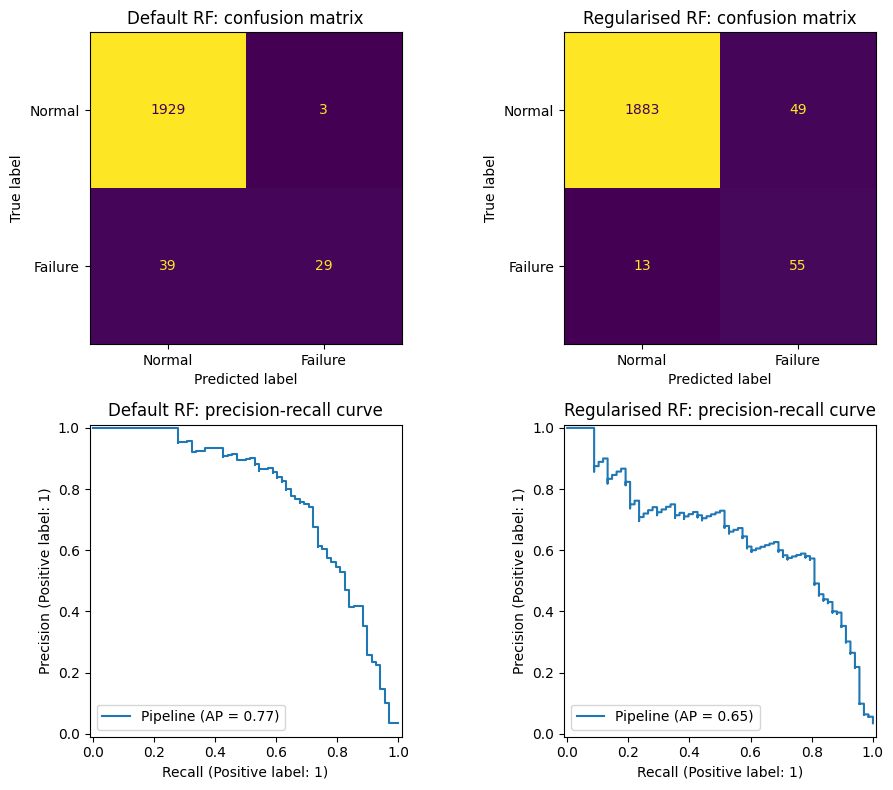

In [4]:
# Confusion matrices and precision-recall curves on the test set
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i, (name, m) in enumerate(models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["Normal", "Failure"]).plot(ax=axes[0, i], colorbar=False)
    axes[0, i].set_title(f"{name}: confusion matrix")
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=axes[1, i])
    axes[1, i].set_title(f"{name}: precision-recall curve")
plt.tight_layout()
plt.show()

## 4. Overfitting or underfitting? Training vs test performance

If a model scores much better on the data it was trained on than on unseen data, it is **overfitting**. If it scores poorly on both, it is **underfitting**. I compare training and test scores, and also use 5-fold stratified cross-validation on the training data. Cross-validation checks that the result does not depend on one lucky split.

In [5]:
train_results = pd.DataFrame({name: metrics(m, X_train, y_train) for name, m in models.items()}).T

comparison = pd.concat({"Train": train_results[["Recall", "F1", "Avg precision"]],
                        "Test":  test_results[["Recall", "F1", "Avg precision"]]}, axis=1)
comparison["F1 gap (train - test)"] = train_results["F1"] - test_results["F1"]
comparison.round(3)

Train                        Test                      \
               Recall     F1 Avg precision Recall    F1 Avg precision   
Default RF       1.00  1.000         1.000  0.426  0.58         0.772   
Regularised RF   0.97  0.742         0.896  0.809  0.64         0.653   

               F1 gap (train - test)  
                                      
Default RF                     0.420  
Regularised RF                 0.102

In [6]:
# 5-fold cross-validation on the training set (train and validation scores)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = {}
for name, m in models.items():
    scores = cross_validate(m, X_train, y_train, cv=cv,
                            scoring=["f1", "recall", "precision"], return_train_score=True)
    cv_summary[name] = {
        "CV train F1": scores["train_f1"].mean(),
        "CV validation F1": scores["test_f1"].mean(),
        "CV validation F1 (std)": scores["test_f1"].std(),
        "CV validation recall": scores["test_recall"].mean(),
    }
cv_table = pd.DataFrame(cv_summary).T
cv_table.round(3)

,CV train F1,CV validation F1,CV validation F1 (std),CV validation recall
Default RF,1.000,0.523,0.044,0.369
Regularised RF,0.755,0.618,0.013,0.745


In [7]:
# Simple automatic reading of the results (a rule of thumb, not a strict test)
for name in models:
    tr, te = train_results.loc[name, "F1"], test_results.loc[name, "F1"]
    gap = tr - te
    if gap > 0.10:
        verdict = "likely OVERFITTING (large gap between train and test F1)"
    elif tr < 0.5 and te < 0.5:
        verdict = "possible UNDERFITTING (low F1 on both train and test)"
    else:
        verdict = "no strong sign of over- or underfitting"
    print(f"{name:15s} train F1 = {tr:.3f} | test F1 = {te:.3f} | gap = {gap:.3f} -> {verdict}")

Default RF      train F1 = 1.000 | test F1 = 0.580 | gap = 0.420 -> likely OVERFITTING (large gap between train and test F1)
Regularised RF  train F1 = 0.742 | test F1 = 0.640 | gap = 0.102 -> likely OVERFITTING (large gap between train and test F1)


**Commentary on overfitting and underfitting**

Read this with the tables above.
- A default Random Forest can typically fit its training data almost perfectly, so its training F1 is close to 1.0 while its test F1 is lower. A large gap means overfitting.
- Limiting tree depth and leaf size usually narrows the gap, sometimes at a small cost in training score. Compare the F1 gap of the two models in the table.
- If both training and test F1 were low, the model would be underfitting, meaning it is too simple or lacks informative features.
- Cross-validation gives a more stable estimate than one split. The standard deviation of the validation F1 shows how much the score changes between folds, which is expected to be noticeable because the test set holds few failures.

I select the final model by **cross-validation F1 on the training data**, not by the test set, so the test set stays a fair final check.

In [8]:
# Choose the final model using cross-validation (NOT the test set)
best_name = cv_table["CV validation F1"].idxmax()
final_model = models[best_name]
print("Final model:", best_name)

Final model: Regularised RF


## 5. What influences the model's predictions? Feature importance

I use **permutation importance** on the test set. It shuffles one feature at a time and measures how much the score drops. A large drop means the model relies on that feature. It works on the original columns (so `Type` stays one feature) and is more reliable than the built-in Random Forest importance, which can favour features with many distinct values. I score it with average precision, because it suits imbalanced data.

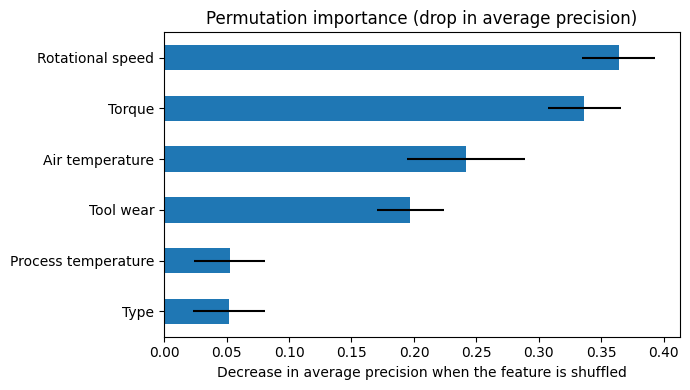

,Importance,Std
Rotational speed,0.3638,0.0295
Torque,0.3364,0.0294
Air temperature,0.2416,0.0473
Tool wear,0.1969,0.0267
Process temperature,0.0525,0.0283
Type,0.0518,0.0287


In [9]:
perm = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=42, n_jobs=-1)

imp = pd.DataFrame({"Importance": perm.importances_mean, "Std": perm.importances_std},
                   index=X_test.columns).sort_values("Importance", ascending=False)

imp["Importance"].sort_values().plot(kind="barh", xerr=imp.loc[imp["Importance"].sort_values().index, "Std"],
                                     figsize=(7, 4), title="Permutation importance (drop in average precision)")
plt.xlabel("Decrease in average precision when the feature is shuffled")
plt.tight_layout()
plt.show()
imp.round(4)

Top numeric features: ['Rotational speed', 'Torque', 'Air temperature']


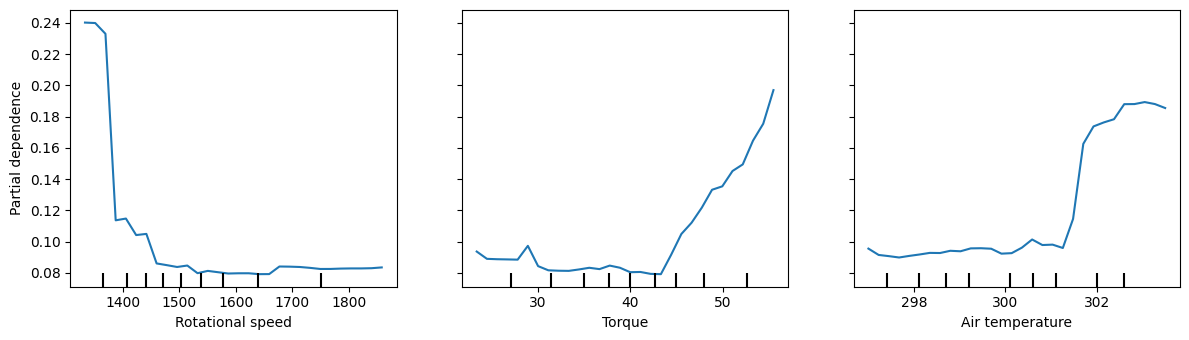

In [10]:
# Partial dependence: how does the predicted failure probability change with each top feature?
top_numeric = [f for f in imp.index if f in numeric_cols][:3]
print("Top numeric features:", top_numeric)

fig, ax = plt.subplots(figsize=(12, 3.5))
PartialDependenceDisplay.from_estimator(final_model, X_test, top_numeric, ax=ax,
                                        grid_resolution=30, kind="average")
plt.tight_layout()
plt.show()

## 6. Do the results make sense scientifically?

**Domain check.** The AI4I dataset is synthetic, and its documentation (https://archive.ics.uci.edu/dataset/601) describes the rules used to create failures. As I understand it, these are:
- **Tool wear failure:** when tool wear reaches a certain level
- **Heat dissipation failure:** when the air-to-process temperature difference is small and the rotational speed is low
- **Power failure:** when torque multiplied by rotational speed (mechanical power) is too low or too high
- **Overstrain failure:** when tool wear multiplied by torque is too high
- **Random failures:** a small chance that is independent of the sensors

I should confirm these details in the documentation before relying on them.

**What I should expect and check in my own output.**
- Features linked to mechanical load and wear (**torque, rotational speed, tool wear**) should rank high, because several failure rules depend on them. If they rank near the top, the model matches the physics.
- The two temperature features may rank lower on their own, because the heat rule depends on their *difference*, not on either value alone. This is a hint for **feature engineering**: adding a "process minus air temperature" feature and a "power = torque × speed" feature may help the model.
- `Type` should matter little, since it only changes a threshold in one rule.
- Partial dependence plots should show failure probability rising at extreme values, such as high torque or high tool wear, which is physically sensible for overstrain and wear. Random failures have no cause in the data, so no model can predict them, which puts a ceiling on the achievable recall.

If an unexpected feature ranks highly, I would suspect data leakage or a quirk of the synthetic data before trusting it.

**Link to infant warmers.** The analogy is that load, ageing and the heater-to-ambient temperature difference should drive faults. This is only an analogy, because the model has not seen real warmer data.

## 7. Save the model and use it on new data

I save the whole pipeline (preprocessing and model) with `joblib`, so that the same scaling and encoding are applied when predicting. I then load it back in the same way a separate program would, and predict on new, made-up machine readings.

In [11]:
MODEL_FILE = "failure_model.joblib"

# Save the pipeline together with the library version it was built with
joblib.dump({"model": final_model, "sklearn_version": sklearn.__version__,
             "features": numeric_cols + categorical_cols}, MODEL_FILE, compress=3)
print("Saved:", MODEL_FILE)

# ---- Later / elsewhere: load and use ----
saved = joblib.load(MODEL_FILE)
loaded_model = saved["model"]
print("Loaded. Built with scikit-learn", saved["sklearn_version"], "| running", sklearn.__version__)

def predict_failure(new_data, threshold=0.5):
    """Return failure probability and a normal/failure call for new sensor readings."""
    new_data = new_data[saved["features"]]            # keep the expected column order
    prob = loaded_model.predict_proba(new_data)[:, 1]
    return pd.DataFrame({"Failure probability": prob.round(3),
                         "Prediction": np.where(prob >= threshold, "FAILURE RISK", "Normal")},
                        index=new_data.index)

# New, made-up readings (illustration only, not real measurements)
new_machines = pd.DataFrame({
    "Air temperature":     [298.5, 301.0, 300.2],
    "Process temperature": [309.0, 310.5, 310.0],
    "Rotational speed":    [1550, 1300, 2300],
    "Torque":              [40.0, 65.0, 15.0],
    "Tool wear":           [50, 220, 10],
    "Type":                ["M", "L", "H"],
}, index=["Machine A", "Machine B", "Machine C"])

pd.concat([new_machines, predict_failure(new_machines)], axis=1)

Saved: failure_model.joblib
Loaded. Built with scikit-learn 1.6.1 | running 1.6.1


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Type,Failure probability,Prediction
Machine A,298.5,309.0,1550,40.0,50,M,0.013,Normal
Machine B,301.0,310.5,1300,65.0,220,L,0.919,FAILURE RISK
Machine C,300.2,310.0,2300,15.0,10,H,0.304,Normal


In [12]:
# Optional in Colab: download the model file so it can be committed to GitHub
# from google.colab import files
# files.download(MODEL_FILE)

## 8. Deployment discussion

**How the model could eventually be used in practice**
- As a **decision-support tool for technicians**, not as an automatic controller. The model would score sensor readings from warmers, for example on a small gateway computer or a hospital server that collects logged data, and flag units with a high failure risk for inspection or preventive maintenance.
- It should never be able to switch off or change the heater by itself. The warmer's own hardware safety limits and alarms must stay independent of the model.
- A safe rollout would start in **"shadow mode"**, where the model makes predictions but nobody acts on them, so its alerts can be compared with what technicians actually find.
- Before any real use, the model must be **retrained on real infant warmer data**. The current model was trained on synthetic data from a different machine.

**What would need to be monitored after deployment**
- **Input data drift:** whether sensor readings still look like the training data, for example after a sensor is replaced or recalibrated, or when the ambient conditions change.
- **Model performance:** recall, precision and the false-alarm rate, checked against confirmed faults in service records.
- **Missed failures:** each failure the model did not flag should be reviewed, because these are the most dangerous errors.
- **Alert fatigue:** whether technicians act on alerts or start ignoring them.
- **Data quality:** missing readings, stuck sensors and logging errors.
- **Versions and logging:** which model and software version produced each prediction, and a schedule for retraining.

**One limitation or risk**
The biggest risk is a **false sense of security from missed failures (false negatives)**. Failures are rare, so the model sees few examples, and a "Normal" prediction can be wrong. If staff trust it too much and skip routine checks, a real fault in a life-supporting device could go unnoticed. A second, related limitation is that the model was trained on synthetic data from a milling machine, so its results say little about how it would perform on infant warmers.